# <center> TRABALHO DE CONCLUSÃO DE CURSO </center>
## <center> Especialização em Ciência de Dados - Turma 2018.1 - Facens </center>



|**Orientador:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

Resumo:...

# 1 - Análise dos dados

Para o presente trabalho será utilizado um conjunto de datasets, sendo eles:

**Fotovoltaico.csv** - referente a dados da estação fotovoltaica composta por quatro inversores solares.

**Meteorologico.csv** - referente a dados da estação meteorológica.


In [1]:
#CÉLULA TCC-01
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter, MinuteLocator, DayLocator

In [2]:
#CÉLULA TCC-02
#Método responsável por carregar os arquivos csv's
def loadDataFile(fileName, DateTimeIndex):
    #Convertendo a coluna de data para index e para o formato de DateTime
    if DateTimeIndex:    
        return pd.read_csv(fileName, encoding='utf-8', index_col=0, parse_dates=[0])
    else:
        return pd.read_csv(fileName, encoding='utf-8')

In [3]:
#CÉLULA TCC-03
# Método responsável por salvar o arquivo em formato csv
def saveDataFile(dataFrame, fileName):
    dataFrame.to_csv(fileName, encoding='utf-8', sep=',', index=False)

In [4]:
#CÉLULA TCC-04
#Método responsável por plotar os dataFrames
def showDataPlot(dataFrame):
    #plt.plot(dfFT.index,dfFT.energia_dia, 'ro-')
    #plt.plot(dfFT.index,dfFT.potencia, 'b+-')
    plt.grid()
    plt.plot(dataFrame)
    plt.gca().legend(dataFrame.columns)
    plt.show()

## 1.1 - Análise do dataset fotovoltaico

In [5]:
#CÉLULA TCC-0
dataSetFotoVoltaico = ['Fotovoltaico_Abr_2019.csv',
'Fotovoltaico_Ago_2018.csv',
'Fotovoltaico_Dez_2018.csv',
'Fotovoltaico_Fev_2019.csv',
'Fotovoltaico_Jan_2019.csv',
'Fotovoltaico_Jul_2018.csv',
'Fotovoltaico_Jun_2019.csv',
'Fotovoltaico_Mai_2019.csv',
'Fotovoltaico_Mar_2019.csv',
'Fotovoltaico_Nov_2018.csv',
'Fotovoltaico_Out_2018.csv',
'Fotovoltaico_Sep_2018.csv']

In [7]:
#CÉLULA TCC-0
for idx, data in  enumerate(dataSetFotoVoltaico):
    path = '{}'.format(data)
    if idx == 0:
        dfRawFoto = loadDataFile(path, True)
    else:
        dfRawFoto = pd.concat([dfRawFoto, loadDataFile(path, True)])
dfRawFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8022697 entries, 2019-04-30 23:59:57.940000 to 2018-09-01 00:00:02.713000
Data columns (total 8 columns):
painel           float64
energia_dia      float64
energia_ano      float64
energia_total    float64
potencia         float64
power_led        int64
solarnet_led     int64
solarweb_led     int64
dtypes: float64(5), int64(3)
memory usage: 550.9 MB


In [8]:
#CÉLULA TCC-
#Selecionando campos
dfRawFoto.drop({
    #'painel',#Campo representando cada inversor instalado, ou seja, 4 inversores, podendo ser 1,2,3 e 4;
    #'energia_dia',#Campo representando a energia acumulada por dia, retirado do próprio inversor (Wh);
    'energia_ano',#Campo representando a energia acumulada por ano (Wh);
    'energia_total',#Campo representando a energia acumulada desde o inicio da operação do painel (Wh);
    #'potencia', #Potência instantâne, é a potência da associação de módulos conectados ao inversor (W);
    'power_led', #Led ...
    'solarnet_led', #Led ...
    'solarweb_led' #Led ...
    },axis=1, inplace=True)

In [9]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawFoto.dropna(inplace=True)

In [10]:
#CÉLULA TCC-
#Selecionando apenas o painel 1
dfRawFoto1 = dfRawFoto[dfRawFoto.painel == 1]

In [11]:
#CÉLULA TCC-
#Ordenando o data set pelo index, que representa o campo data
dfRawFoto1 = dfRawFoto1.sort_index()
dfRawFoto1.head()

,painel,energia_dia,potencia
data,,,
2018-07-01 00:00:06.897,1.0,45990.0,0.0
2018-07-01 00:00:10.697,1.0,45990.0,0.0
2018-07-01 00:00:28.477,1.0,45990.0,0.0
2018-07-01 00:00:48.993,1.0,45990.0,0.0
2018-07-01 00:01:07.387,1.0,45990.0,0.0


In [12]:
#CÉLULA TCC-
dfRawFoto1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1881412 entries, 2018-07-01 00:00:06.897000 to 2019-06-19 13:31:31.123000
Data columns (total 3 columns):
painel         float64
energia_dia    float64
potencia       float64
dtypes: float64(3)
memory usage: 57.4 MB


In [13]:
#CÉLULA TCC-
#dfRawFoto1['energia'] = [dfRawFoto1['energia_dia'] - dfRawFoto1['energia_dia'].shift(1) if dfRawFoto1['potencia'] >= 0 else 0.0]

dfRawFoto1['energia'] = np.where(dfRawFoto1['potencia'] > 0, dfRawFoto1['energia_dia'] - dfRawFoto1['energia_dia'].shift(1), 0)

In [14]:
#CÉLULA TCC-
dfRawFoto1[dfRawFoto1 < 0] = 0

In [15]:
#CÉLULA TCC-
dfRawFoto1.drop({'energia_dia', 'potencia'},axis=1, inplace=True)

In [16]:
#CÉLULA TCC-
dfRawFoto1.fillna(0, inplace=True)

In [17]:
#CÉLULA TCC-
dfRawFoto1.isna().sum()

painel     0
energia    0
dtype: int64

In [18]:
for m in dfRawFoto1.groupby(by=[dfRawFoto1.index.month]):
    print(m[1].resample('D').agg({"painel":'size',"energia":'sum'}).painel < (5760 * 0.8))

data
2019-01-01    False
2019-01-02    False
2019-01-03    False
2019-01-04    False
2019-01-05    False
2019-01-06    False
2019-01-07    False
2019-01-08    False
2019-01-09    False
2019-01-10    False
2019-01-11    False
2019-01-12    False
2019-01-13    False
2019-01-14    False
2019-01-15    False
2019-01-16    False
2019-01-17    False
2019-01-18    False
2019-01-19    False
2019-01-20    False
2019-01-21    False
2019-01-22    False
2019-01-23    False
2019-01-24    False
2019-01-25    False
2019-01-26    False
2019-01-27    False
2019-01-28    False
2019-01-29    False
2019-01-30     True
2019-01-31     True
Freq: D, Name: painel, dtype: bool
data
2019-02-01    False
2019-02-02    False
2019-02-03    False
2019-02-04    False
2019-02-05     True
2019-02-06     True
2019-02-07     True
2019-02-08     True
2019-02-09    False
2019-02-10    False
2019-02-11    False
2019-02-12    False
2019-02-13    False
2019-02-14    False
2019-02-15    False
2019-02-16    False
2019-02-17    F

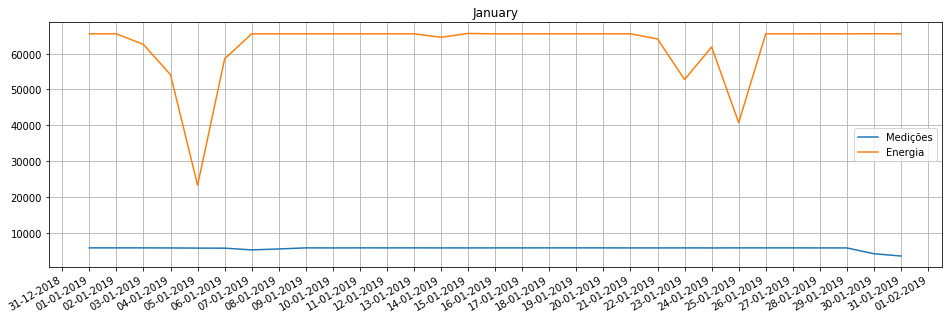

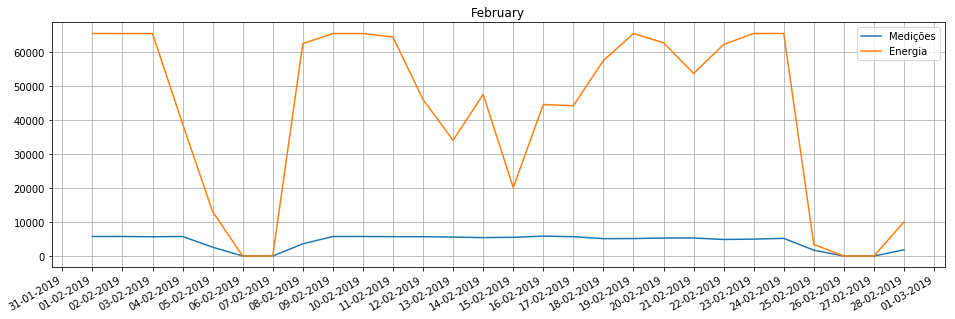

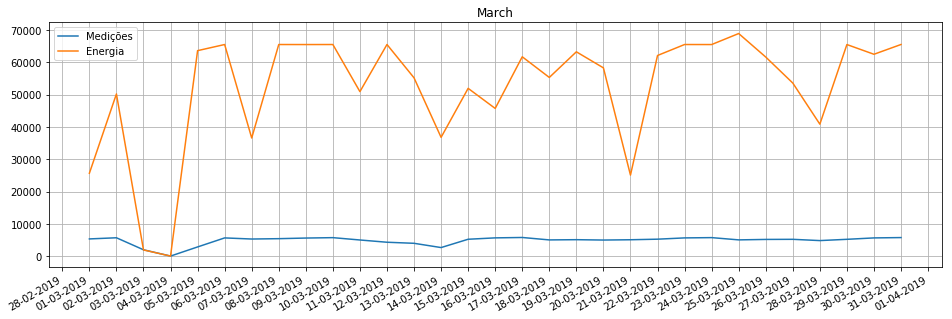

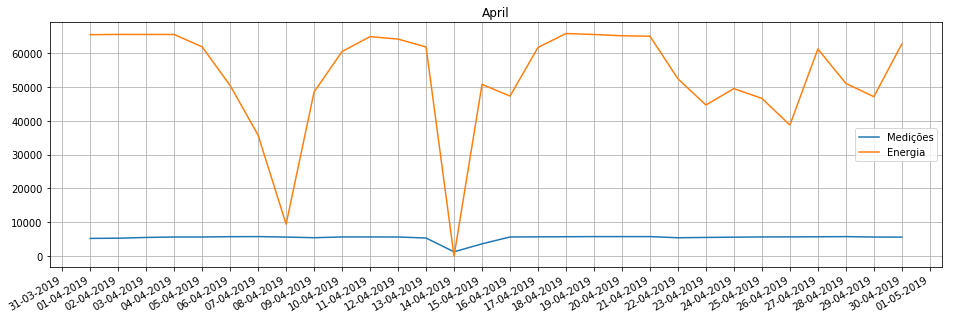

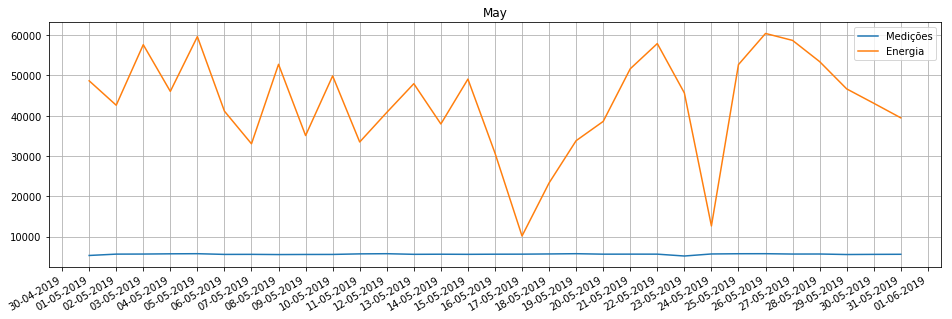

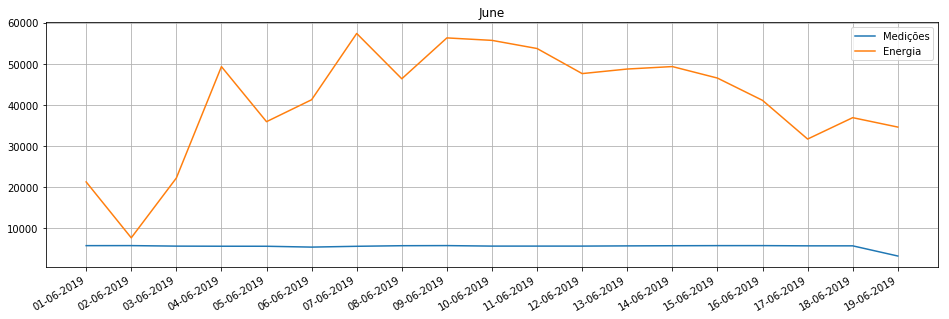

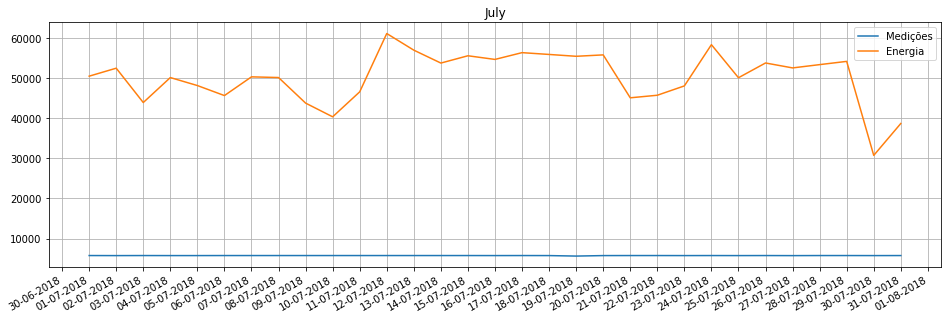

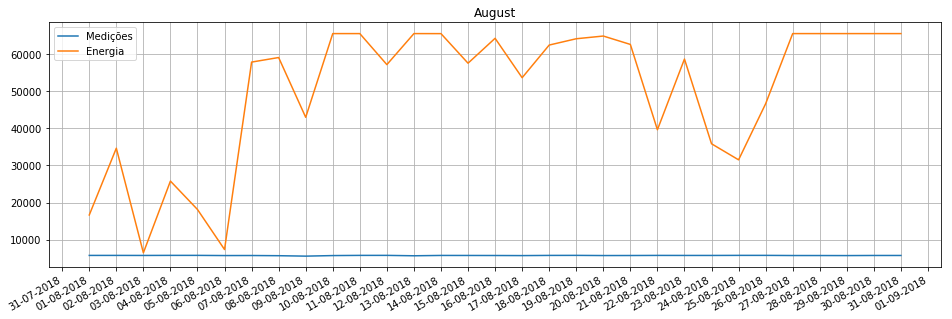

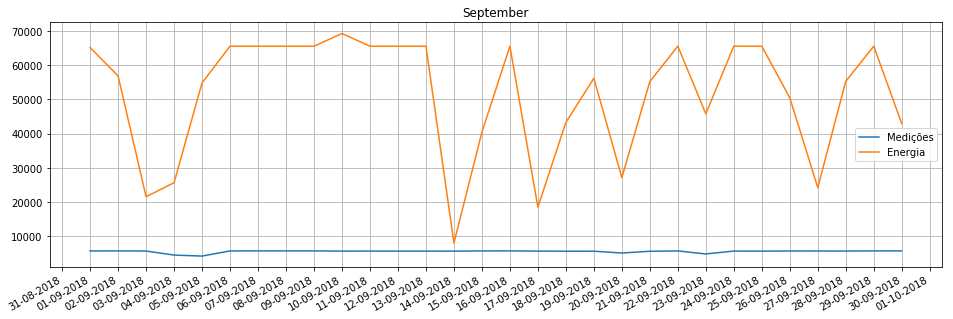

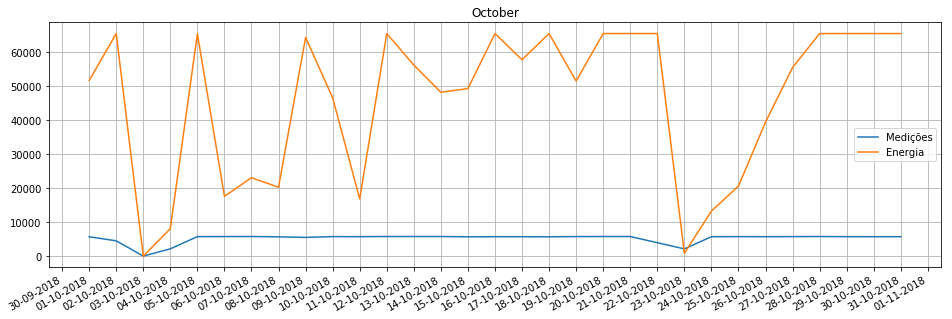

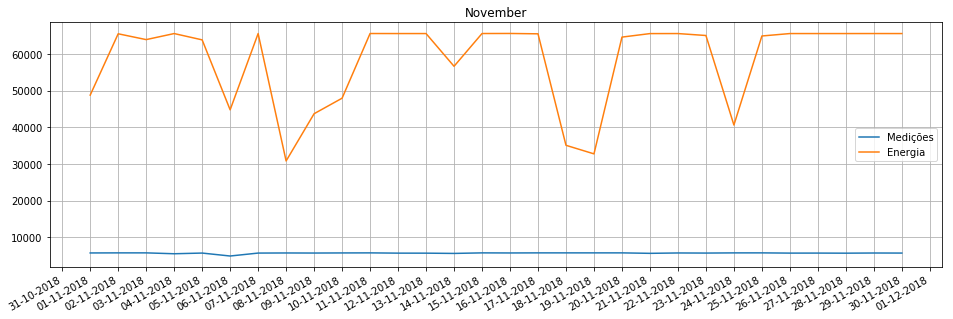

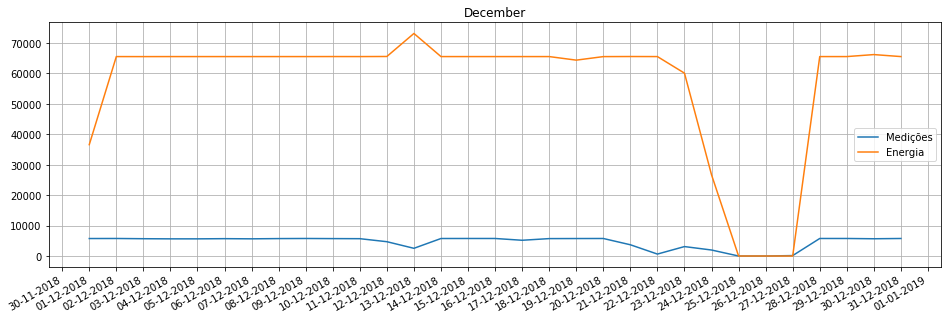

In [19]:
#CÉLULA TCC-
#deixar somente energia ????????
for m in dfRawFoto1.groupby(by=[dfRawFoto1.index.month]):
    plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1].resample('D').agg({"painel":'size',"energia":'sum'}))
    plt.title(m[1].index.month_name()[0])
    #plt.gca().legend(m[1].columns)
    plt.gca().legend(["Medições","Energia"])
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

In [20]:
a = dfRawFoto1.reset_index()[(dfRawFoto1.reset_index()['data'] >= '2019-02-16 23:30:00') & (dfRawFoto1.reset_index()['data'] <= '2019-02-16 23:59:59') ]
a.set_index('data',inplace=True)
a.head(50)

,painel,energia
data,,
2019-02-16 23:30:06.350,1.0,0.0
2019-02-16 23:30:08.400,1.0,0.0
2019-02-16 23:30:09.900,1.0,0.0
2019-02-16 23:30:16.287,1.0,0.0
2019-02-16 23:30:27.187,1.0,0.0
2019-02-16 23:30:34.717,1.0,0.0
2019-02-16 23:30:47.877,1.0,0.0
2019-02-16 23:30:55.350,1.0,0.0
2019-02-16 23:31:06.773,1.0,0.0


In [21]:
c = dfRawFoto1.reset_index()[(dfRawFoto1.reset_index()['data'] >= '2019-02-16 00:00:00') & (dfRawFoto1.reset_index()['data'] <= '2019-02-16 23:59:59') ]
c.energia.sum()

44630.0

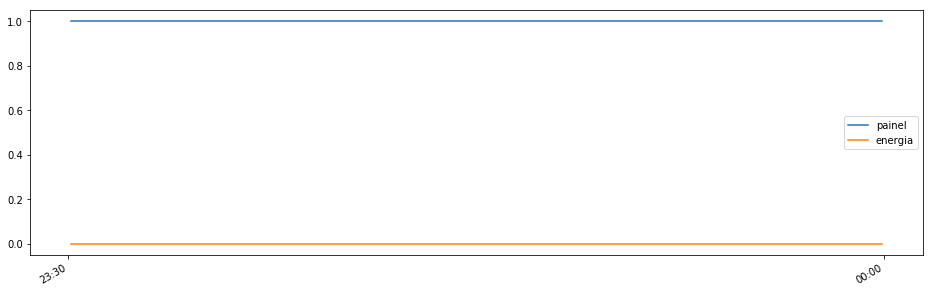

In [23]:
plt.figure(figsize=(16,5))
plt.grid()
#showDataPlot(dfRawFoto1)
##Dividir gráficos
plt.grid()
plt.plot(a)
plt.gca().legend(a.columns)
plt.gca().xaxis.set_major_locator(MinuteLocator(byminute=(0,30,0)))#DayLocator(interval=5)
plt.gca().xaxis.set_major_formatter(DateFormatter('%H:%M'))
plt.gcf().autofmt_xdate()
plt.show()

## 1.2 - Análise do dataset meteorológico

In [24]:
#CÉLULA TCC-0
dataSetMeteorologico = ['Meteorologico_Abr_2019.csv',
'Meteorologico_Ago_2018.csv',
'Meteorologico_Dez_2018.csv',
'Meteorologico_Fev_2019.csv',
'Meteorologico_Jan_2019.csv',
'Meteorologico_Jul_2018.csv',
'Meteorologico_Jun_2019.csv',
'Meteorologico_Mai_2019.csv',
'Meteorologico_Mar_2019.csv',
'Meteorologico_Nov_2018.csv',
'Meteorologico_Out_2018.csv',
'Meteorologico_Sep_2018.csv']

In [26]:
#CÉLULA TCC-0
for idx, data in  enumerate(dataSetMeteorologico):
    path = '{}'.format(data)
    if idx == 0:
        dfRawMete = loadDataFile(path, True)
    else:
        dfRawMete = pd.concat([dfRawMete, loadDataFile(path, True)])
dfRawMete.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 50502 entries, 2019-04-01 00:00:06 to 2018-09-01 00:00:06
Data columns (total 14 columns):
deficit_vapor_vmin         50502 non-null float64
deficit_vapor_vmedio       50502 non-null float64
ponto_orvalho_vmin         50502 non-null float64
ponto_orvalho_vmedio       50502 non-null float64
precipitacao_valor         50502 non-null float64
radiacao_solar_valor       50497 non-null float64
temperatura_ar_vmin        50502 non-null float64
temperatura_ar_vmedio      50502 non-null float64
temperatura_ar_vmax        50502 non-null float64
umidade_ar_vmin            50502 non-null float64
umidade_ar_vmedio          50502 non-null float64
umidade_ar_vmax            50502 non-null float64
velocidade_vento_vmedio    50502 non-null float64
velocidade_vento_vmax      50502 non-null float64
dtypes: float64(14)
memory usage: 5.8 MB


In [27]:
#CÉLULA TCC-
#Selecionando campos
dfRawMete.drop({
    #'deficit_vapor_vmin',
    #'deficit_vapor_vmedio',
    #'ponto_orvalho_vmin',
    #'ponto_orvalho_vmedio',
    #'precipitacao_valor',
    #'radiacao_solar_valor',
    #'temperatura_ar_vmin',#
    #'temperatura_ar_vmedio',
    #'temperatura_ar_vmax',#
    #'umidade_ar_vmin',#
    #'umidade_ar_vmedio',
    #'umidade_ar_vmax',#
    #'velocidade_vento_vmedio',
    #'velocidade_vento_vmax'
    },axis=1, inplace=True)

In [28]:
#CÉLULA TCC-
#Removendo campos vazios
dfRawMete.dropna(inplace=True)

In [29]:
#CÉLULA TCC-
dfRawMete.head()

,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
data,,,,,,,,,,,,,,
2019-04-01 00:00:06,0.56,0.56,17.0,17.0,0.0,0.0,21.18,21.20,21.22,77.20,77.26,77.33,0.7,0.8
2019-04-01 00:10:07,0.57,0.57,17.1,17.1,0.0,0.0,21.25,21.25,21.25,77.35,77.35,77.35,0.8,0.8
2019-04-01 00:20:06,0.58,0.58,17.1,17.1,0.0,0.0,21.29,21.29,21.30,77.04,77.05,77.07,0.9,1.1
2019-04-01 00:30:06,0.59,0.59,17.0,17.0,0.0,0.0,21.33,21.34,21.36,76.31,76.45,76.60,0.9,1.0
2019-04-01 00:40:07,0.60,0.60,16.9,16.9,0.0,0.0,21.36,21.37,21.39,76.00,76.05,76.10,0.8,1.0


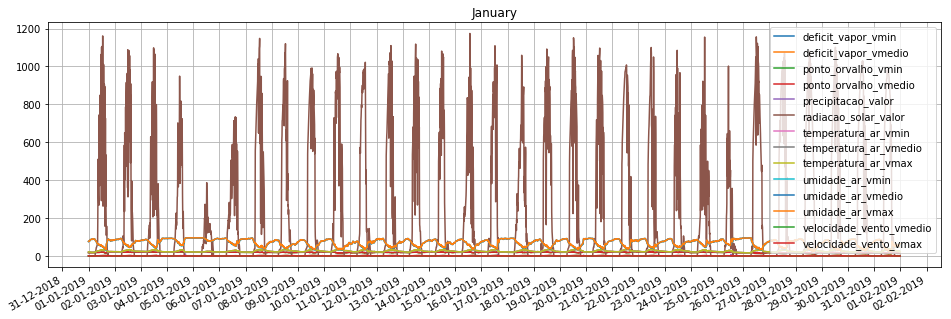

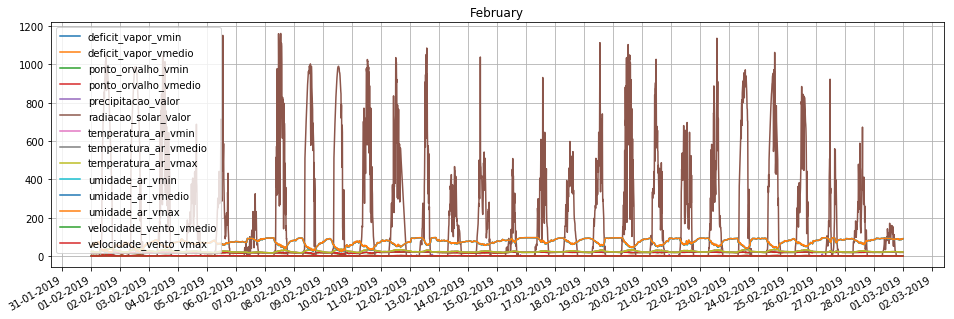

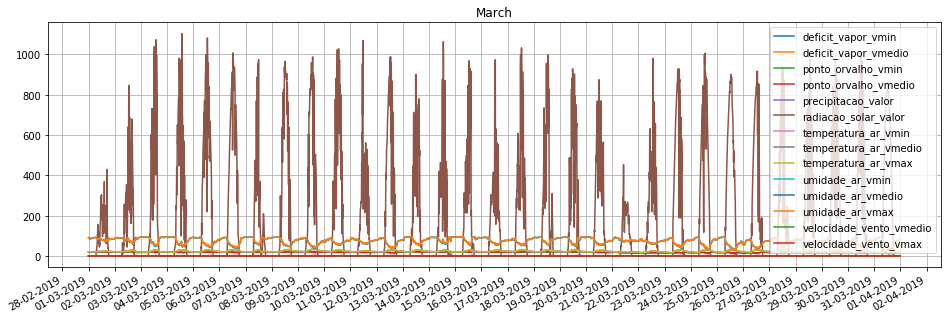

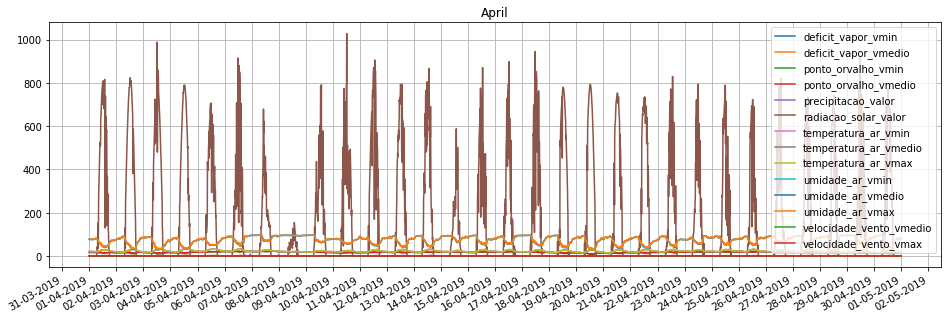

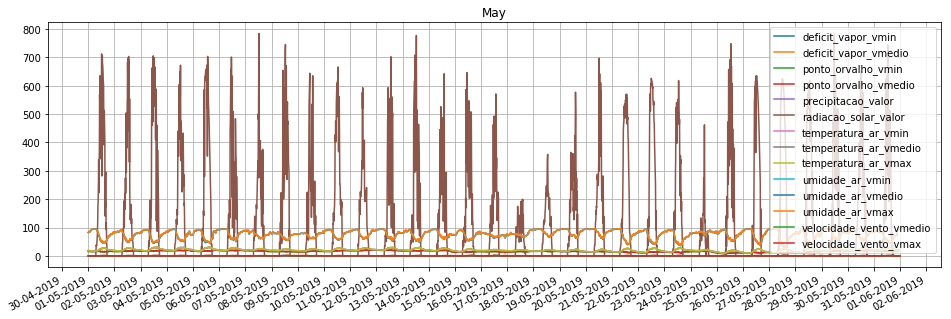

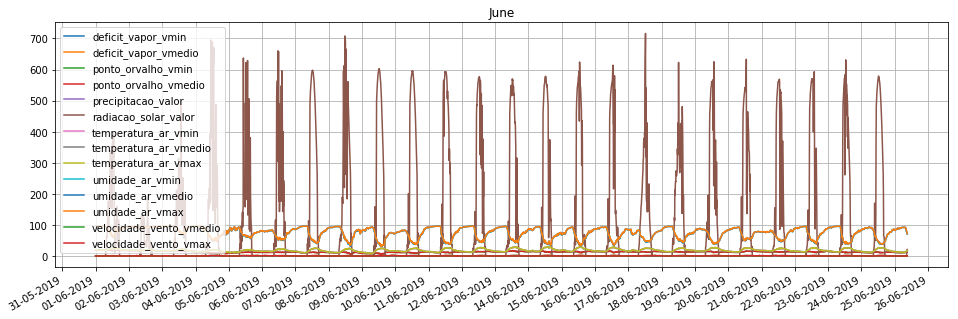

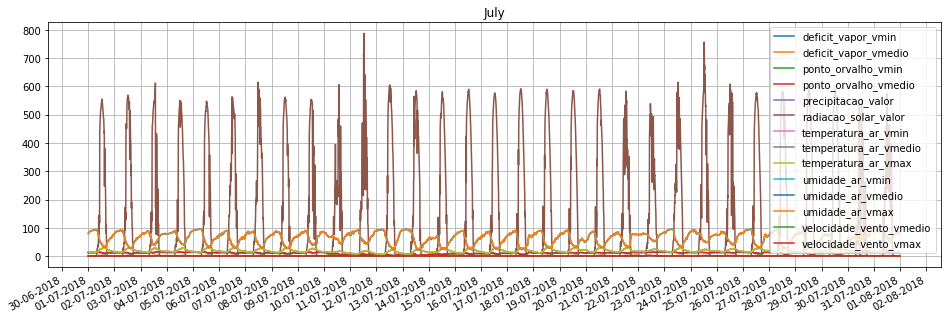

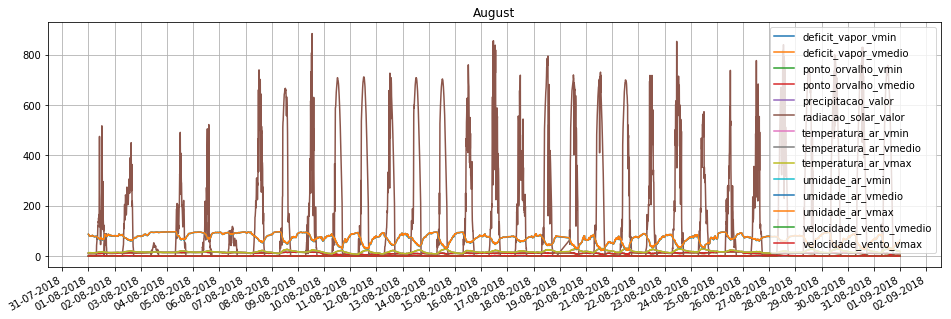

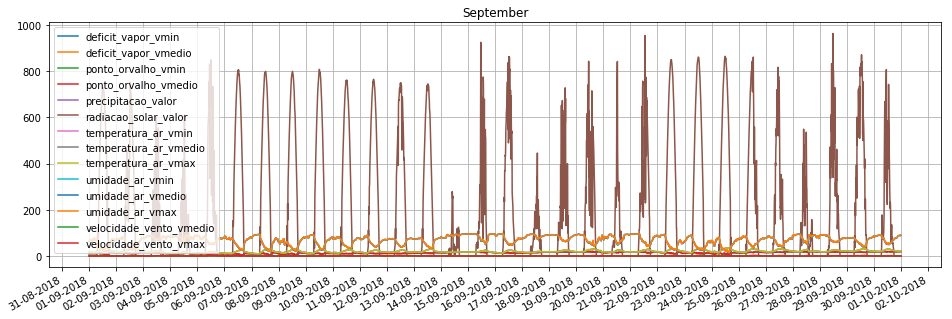

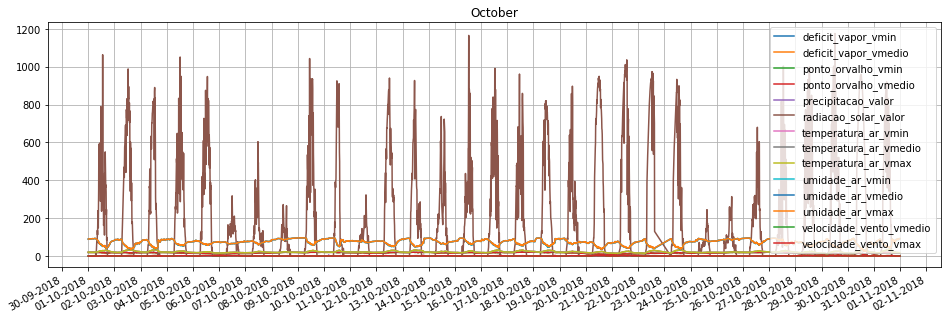

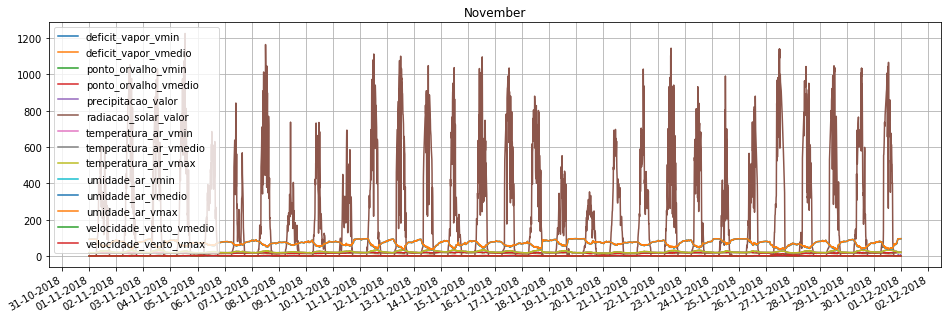

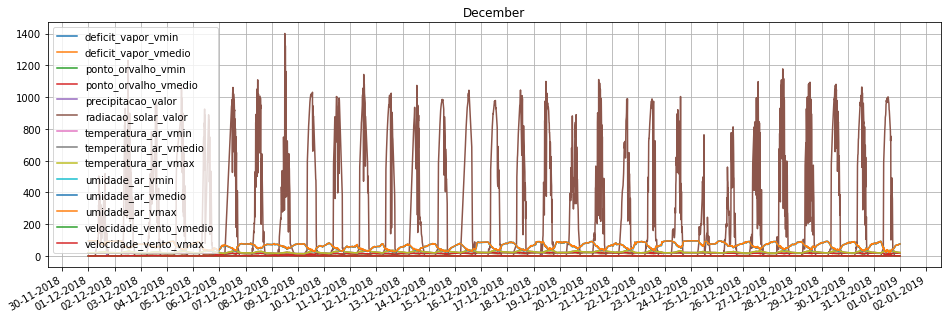

In [30]:
#CÉLULA TCC-
#plt.figure(figsize=(16,5))
#showDataPlot(dfRawMete)
for m in dfRawMete.groupby(by=[dfRawMete.index.month]):
    plt.figure(figsize=(16,5))
    plt.grid()
    plt.plot(m[1])
    plt.title(m[1].index.month_name()[0])
    plt.gca().legend(m[1].columns)
    plt.gca().xaxis.set_major_locator(DayLocator())#DayLocator(interval=5)
    plt.gca().xaxis.set_major_formatter(DateFormatter('%d-%m-%Y'))
    plt.gcf().autofmt_xdate()
    plt.show()

## 1.3 - Unificando os datasets

Como os datasets apresentam medições distintas em tempos e frequência diferentes, como demonstra a representação abaixo:
* Fotovoltaico - apresenta em média 1 medição a cada 15 a 20 segundos, totalizando 240 medições por hora;
* Meteorologico - apresenta em média 1 mediação a cada 10 minutos, totalizando 6 medições por hora;

Será utilizado a tecnica de UpSample para os dados fotovoltaicos afim de centralizar as medições em um tempo maior, e para os dados meteorológicos a tecnica de DownSample para ajustar as medições em períodos faltantes, visando também um mesmo padrão de tempo nos dois datasets.

In [31]:
#CÉLULA TCC-
#D         calendar day frequency
#H         hourly frequency
#T, min    minutely frequency
freq = '10T' #1D - 1 dia,  10T - 10 min

## 1.3.1 - DownSample

In [32]:
dfRawFoto1.head()

,painel,energia
data,,
2018-07-01 00:00:06.897,1.0,0.0
2018-07-01 00:00:10.697,1.0,0.0
2018-07-01 00:00:28.477,1.0,0.0
2018-07-01 00:00:48.993,1.0,0.0
2018-07-01 00:01:07.387,1.0,0.0


In [33]:
#CÉLULA TCC-
downFoto = dfRawFoto1.resample(freq) #de 10 em 10 minutos cravados
newDownFoto = downFoto.agg({
    "painel":'max',
    #"potencia":'mean',
    "energia":'sum'
})
interDownFoto = newDownFoto.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
print(interDownFoto.head())

                     painel  energia
data                                
2018-07-01 00:00:00     1.0      0.0
2018-07-01 00:10:00     1.0      0.0
2018-07-01 00:20:00     1.0      0.0
2018-07-01 00:30:00     1.0      0.0
2018-07-01 00:40:00     1.0      0.0


In [34]:
interDownFoto.head()

,painel,energia
data,,
2018-07-01 00:00:00,1.0,0.0
2018-07-01 00:10:00,1.0,0.0
2018-07-01 00:20:00,1.0,0.0
2018-07-01 00:30:00,1.0,0.0
2018-07-01 00:40:00,1.0,0.0


In [35]:
interDownFoto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 50914 entries, 2018-07-01 00:00:00 to 2019-06-19 13:30:00
Freq: 10T
Data columns (total 2 columns):
painel     50914 non-null float64
energia    50914 non-null float64
dtypes: float64(2)
memory usage: 3.7 MB


In [36]:
dfRawFoto1.isna().sum()

painel     0
energia    0
dtype: int64

In [37]:
from collections import Counter
Counter(dfRawFoto1.reset_index().data.astype('M8[D]'))

Counter({Timestamp('2018-07-01 00:00:00'): 5760,
         Timestamp('2018-07-02 00:00:00'): 5746,
         Timestamp('2018-07-03 00:00:00'): 5760,
         Timestamp('2018-07-04 00:00:00'): 5750,
         Timestamp('2018-07-05 00:00:00'): 5751,
         Timestamp('2018-07-06 00:00:00'): 5760,
         Timestamp('2018-07-07 00:00:00'): 5760,
         Timestamp('2018-07-08 00:00:00'): 5760,
         Timestamp('2018-07-09 00:00:00'): 5760,
         Timestamp('2018-07-10 00:00:00'): 5760,
         Timestamp('2018-07-11 00:00:00'): 5759,
         Timestamp('2018-07-12 00:00:00'): 5760,
         Timestamp('2018-07-13 00:00:00'): 5760,
         Timestamp('2018-07-14 00:00:00'): 5760,
         Timestamp('2018-07-15 00:00:00'): 5760,
         Timestamp('2018-07-16 00:00:00'): 5752,
         Timestamp('2018-07-17 00:00:00'): 5760,
         Timestamp('2018-07-18 00:00:00'): 5751,
         Timestamp('2018-07-19 00:00:00'): 5628,
         Timestamp('2018-07-20 00:00:00'): 5750,
         Timestamp('

In [38]:
a = interDownFoto.reset_index()[(interDownFoto.reset_index()['data'] >= '2018-09-05 09:00:00') & (interDownFoto.reset_index()['data'] <= '2018-09-05 19:00:00') ]
a.set_index('data',inplace=True)
a.head(50)

,painel,energia
data,,
2018-09-05 09:00:00,1.0,1870.0
2018-09-05 09:10:00,1.0,1236.0
2018-09-05 09:20:00,1.0,1041.0
2018-09-05 09:30:00,1.0,2783.0
2018-09-05 09:40:00,1.0,348.0
2018-09-05 09:50:00,1.0,2715.0
2018-09-05 10:00:00,1.0,0.0
2018-09-05 10:10:00,1.0,2430.0
2018-09-05 10:20:00,1.0,0.0


In [39]:
b = interDownFoto.reset_index()[(interDownFoto.reset_index()['data'] >= '2018-09-05 00:00:00') & (interDownFoto.reset_index()['data'] <= '2018-09-05 23:59:59') ]
b.set_index('data',inplace=True)
b.count()

painel     144
energia    144
dtype: int64

In [40]:
c = interDownFoto.reset_index()[(interDownFoto.reset_index()['data'] >= '2019-12-27 00:00:00') & (interDownFoto.reset_index()['data'] <= '2019-12-27 23:59:59') ]
c.set_index('data',inplace=True)
c.energia.sum()
#df[df['column name'].map(len) < 2]

0.0

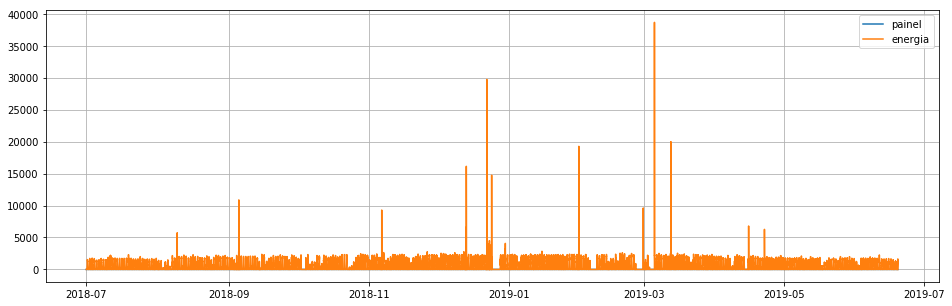

In [41]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownFoto)
##Dividir gráficos

## 1.3.2 - UpSample

In [42]:
#CÉLULA TCC-
downMete = dfRawMete.resample(freq) #de 10 em 10 minutos cravados
newDownMete = downMete.agg({
    'deficit_vapor_vmin':'min',
    'deficit_vapor_vmedio':'mean',
    'ponto_orvalho_vmin':'min',
    'ponto_orvalho_vmedio':'mean',
    'precipitacao_valor':'mean',
    'radiacao_solar_valor':'mean',
    'temperatura_ar_vmin':'min',
    'temperatura_ar_vmedio':'mean',
    'temperatura_ar_vmax':'max',
    'umidade_ar_vmin':'min',
    'umidade_ar_vmedio':'mean',
    'umidade_ar_vmax':'max',
    'velocidade_vento_vmedio':'mean',
    'velocidade_vento_vmax':'max'
})
interDownMete = newDownMete.interpolate(method='linear')
#interpolatedFT = tenMinutesFT.interpolate(method='spline', order=2)#polinomial
interDownMete.head(50)

,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
data,,,,,,,,,,,,,,
2018-07-01 00:00:00,0.32,0.33,11.7,11.7,0.0,0.0,15.12,15.18,15.24,79.73,80.27,80.82,0.0,0.0
2018-07-01 00:10:00,0.31,0.31,12.0,12.0,0.0,0.0,15.21,15.21,15.21,81.63,81.63,81.63,0.0,0.0
2018-07-01 00:20:00,0.32,0.32,12.0,12.0,0.0,0.0,15.17,15.18,15.19,81.42,81.43,81.44,0.0,0.0
2018-07-01 00:30:00,0.31,0.31,11.9,11.9,0.0,0.0,15.03,15.05,15.08,81.60,81.70,81.80,0.0,0.0
2018-07-01 00:40:00,0.28,0.29,11.9,11.9,0.0,0.0,14.79,14.90,15.01,82.36,82.62,82.89,0.0,0.0
2018-07-01 00:50:00,0.25,0.26,11.9,11.9,0.0,0.0,14.51,14.59,14.68,83.66,84.01,84.37,0.0,0.0
2018-07-01 01:00:00,0.24,0.24,12.0,12.1,0.0,0.0,14.54,14.58,14.63,85.20,85.37,85.55,0.0,0.0
2018-07-01 01:10:00,0.24,0.24,12.1,12.1,0.0,0.0,14.61,14.61,14.61,85.29,85.29,85.29,0.0,0.0
2018-07-01 01:20:00,0.23,0.23,12.0,12.0,0.0,0.0,14.44,14.50,14.57,85.66,85.74,85.83,0.0,0.0


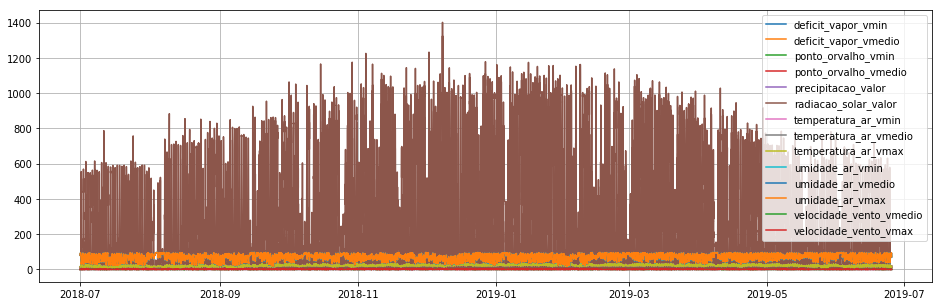

In [43]:
#CÉLULA TCC-
plt.figure(figsize=(16,5))
showDataPlot(interDownMete)
##Dividir gráficos

## 1.3.3 - Realizando o merge

Com os datasets padronizados na mesma freqência de medições, é possível realizar juntar ('merge') os dois em um só dataset, tornando o dataset mais interesssante por conter ambos os registros unificados. 

In [44]:
result = pd.concat([interDownFoto, interDownMete], axis=1, sort=False)

In [45]:
result.isna().sum()

painel                     837
energia                    837
deficit_vapor_vmin           0
deficit_vapor_vmedio         0
ponto_orvalho_vmin           0
ponto_orvalho_vmedio         0
precipitacao_valor           0
radiacao_solar_valor         0
temperatura_ar_vmin          0
temperatura_ar_vmedio        0
temperatura_ar_vmax          0
umidade_ar_vmin              0
umidade_ar_vmedio            0
umidade_ar_vmax              0
velocidade_vento_vmedio      0
velocidade_vento_vmax        0
dtype: int64

In [46]:
result.reset_index(inplace=True)

In [47]:
result.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51751 entries, 0 to 51750
Data columns (total 17 columns):
data                       51751 non-null datetime64[ns]
painel                     50914 non-null float64
energia                    50914 non-null float64
deficit_vapor_vmin         51751 non-null float64
deficit_vapor_vmedio       51751 non-null float64
ponto_orvalho_vmin         51751 non-null float64
ponto_orvalho_vmedio       51751 non-null float64
precipitacao_valor         51751 non-null float64
radiacao_solar_valor       51751 non-null float64
temperatura_ar_vmin        51751 non-null float64
temperatura_ar_vmedio      51751 non-null float64
temperatura_ar_vmax        51751 non-null float64
umidade_ar_vmin            51751 non-null float64
umidade_ar_vmedio          51751 non-null float64
umidade_ar_vmax            51751 non-null float64
velocidade_vento_vmedio    51751 non-null float64
velocidade_vento_vmax      51751 non-null float64
dtypes: datetime64[ns](1), float64

In [48]:
from collections import Counter
Counter(result.data.astype('M8[D]'))

Counter({Timestamp('2018-07-01 00:00:00'): 144,
         Timestamp('2018-07-02 00:00:00'): 144,
         Timestamp('2018-07-03 00:00:00'): 144,
         Timestamp('2018-07-04 00:00:00'): 144,
         Timestamp('2018-07-05 00:00:00'): 144,
         Timestamp('2018-07-06 00:00:00'): 144,
         Timestamp('2018-07-07 00:00:00'): 144,
         Timestamp('2018-07-08 00:00:00'): 144,
         Timestamp('2018-07-09 00:00:00'): 144,
         Timestamp('2018-07-10 00:00:00'): 144,
         Timestamp('2018-07-11 00:00:00'): 144,
         Timestamp('2018-07-12 00:00:00'): 144,
         Timestamp('2018-07-13 00:00:00'): 144,
         Timestamp('2018-07-14 00:00:00'): 144,
         Timestamp('2018-07-15 00:00:00'): 144,
         Timestamp('2018-07-16 00:00:00'): 144,
         Timestamp('2018-07-17 00:00:00'): 144,
         Timestamp('2018-07-18 00:00:00'): 144,
         Timestamp('2018-07-19 00:00:00'): 144,
         Timestamp('2018-07-20 00:00:00'): 144,
         Timestamp('2018-07-21 00:00:00'

In [50]:
saveDataFile(result,'teste01.csv')

In [51]:
#CÉLULA TCC-
dfSet1 = pd.merge(interDownFoto, interDownMete, left_index=True, right_index=True)
#dfSet1['TotalSegundos'] = dfSet1.index.hour * 360 + dfSet1.index.minute * 60 + dfSet1.index.second
dfSet1.reset_index(inplace=True)

In [52]:
#CÉLULA TCC-
dfSet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50914 entries, 0 to 50913
Data columns (total 17 columns):
data                       50914 non-null datetime64[ns]
painel                     50914 non-null float64
energia                    50914 non-null float64
deficit_vapor_vmin         50914 non-null float64
deficit_vapor_vmedio       50914 non-null float64
ponto_orvalho_vmin         50914 non-null float64
ponto_orvalho_vmedio       50914 non-null float64
precipitacao_valor         50914 non-null float64
radiacao_solar_valor       50914 non-null float64
temperatura_ar_vmin        50914 non-null float64
temperatura_ar_vmedio      50914 non-null float64
temperatura_ar_vmax        50914 non-null float64
umidade_ar_vmin            50914 non-null float64
umidade_ar_vmedio          50914 non-null float64
umidade_ar_vmax            50914 non-null float64
velocidade_vento_vmedio    50914 non-null float64
velocidade_vento_vmax      50914 non-null float64
dtypes: datetime64[ns](1), float64

In [55]:
#CÉLULA TCC-
saveDataFile(dfSet1,'FotoMet_Full_DataSets.csv')
#saveDataFile(dfSet1,'input/FotoMet_P1_Sep_2018.csv')

In [56]:
#CÉLULA TCC-
dfSet1 = loadDataFile('FotoMet_Full_DataSets.csv', False)
#dfSet1 = loadDataFile('input/FotoMet_P1_Sep_2018.csv', False)

In [57]:
#CÉLULA TCC-
dfSet1.describe()

,painel,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
count,50914.0,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.00000,50914.000000
mean,1.0,354.750069,0.900712,0.918169,15.720963,15.807127,0.028585,158.790205,21.944977,22.041963,22.143908,70.450939,70.901992,71.358141,0.42705,0.515860
std,0.0,668.396242,0.811608,0.828721,3.682805,3.677190,0.299415,260.214398,5.189477,5.235773,5.284573,17.873431,17.649899,17.441770,0.53725,0.589403
min,1.0,0.000000,0.040000,0.040000,0.100000,0.500000,0.000000,0.000000,5.100000,5.140000,5.180000,14.180000,15.560000,15.690000,0.00000,0.000000
25%,1.0,0.000000,0.300000,0.310000,13.000000,13.000000,0.000000,0.000000,18.580000,18.630000,18.690000,58.040000,58.700000,59.390000,0.00000,0.000000
50%,1.0,0.000000,0.600000,0.610000,16.400000,16.500000,0.000000,0.000000,21.470000,21.540000,21.610000,73.730000,74.090000,74.500000,0.20000,0.300000
75%,1.0,570.000000,1.270000,1.300000,18.800000,18.800000,0.000000,231.000000,25.383553,25.530000,25.650000,84.840000,85.190000,85.580000,0.70000,0.800000
max,1.0,38672.000000,5.420000,5.440000,24.600000,24.600000,12.200000,1401.000000,38.710000,38.820000,38.940000,96.800000,96.800000,96.810000,3.70000,4.600000


In [58]:
dfSet1[(dfSet1['data'] >= '2018-09-05 00:00:00') & (dfSet1['data'] <= '2018-09-05 23:59:59')].energia.sum()

54820.0

In [59]:
dfSet1[(dfSet1['data'] == '2018-09-05')].energia.sum()

0.0

## 2 - Normalização

Descrição ...

In [60]:
#CÉLULA TCC-
df = dfSet1.drop(['data'],axis=1)

In [61]:
#CÉLULA TCC-
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler()
df[df.columns] = min_max_scaler.fit_transform(df[df.columns])
df.describe()

,painel,energia,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
count,50914.0,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000,50914.000000
mean,0.0,0.009173,0.159984,0.162624,0.637590,0.635150,0.002343,0.113341,0.501189,0.501840,0.502485,0.681081,0.681216,0.686244,0.115419,0.112143
std,0.0,0.017284,0.150857,0.153467,0.150319,0.152581,0.024542,0.185735,0.154403,0.155456,0.156534,0.216333,0.217256,0.215012,0.145203,0.128131
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,0.048327,0.050000,0.526531,0.518672,0.000000,0.000000,0.401071,0.400534,0.400178,0.530864,0.531019,0.538708,0.000000,0.000000
50%,0.0,0.000000,0.104089,0.105556,0.665306,0.663900,0.000000,0.000000,0.487057,0.486936,0.486671,0.720770,0.720458,0.724975,0.054054,0.065217
75%,0.0,0.014739,0.228625,0.233333,0.763265,0.759336,0.000000,0.164882,0.603498,0.605404,0.606339,0.855241,0.857090,0.861563,0.189189,0.173913
max,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [44]:
#from sklearn.preprocessing import StandardScaler
#scaler = StandardScaler()
#df[df.columns] = scaler.fit_transform(df[df.columns])
#df.describe()

## 3 - Treinamento do modelo

Descrição ...

In [62]:
#CÉLULA TCC-
import seaborn as sns

from sklearn import model_selection
from sklearn import linear_model
from sklearn.ensemble import RandomForestRegressor

from sklearn import metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [63]:
#CÉLULA TCC-
def showPairPlot(dataFrame):

    pairPlot = sns.pairplot(
        dataFrame,
        size=2.0,
        aspect=1.4,
        plot_kws=dict(edgecolor="k", linewidth=0.2),
        diag_kws=dict(shade=True),        
        diag_kind="kde",
    )               
                 
    fig = pairPlot.fig
    fig.subplots_adjust(top=0.95)
    fig.suptitle(
        'Análise de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [64]:
#CÉLULA TCC-
def showHeatMap(dataFrame):
    
    fig, (ax) = plt.subplots(1, 1, figsize=(11,7))
    heatMap = sns.heatmap(
        dataFrame.corr(), 
        ax=ax,           
        cmap="coolwarm",
        annot=True, 
        fmt='.2f',
        linewidths=.07
    )

    fig.suptitle(
        'Correlação de parâmetros', 
        fontsize=13, 
        fontweight='bold'
    )

In [65]:
#CÉLULA TCC-
def showResultPlot(y_pred,y_test):
    plt.figure(figsize=(17,7))
    y_pred = y_pred.T

    plt.plot(range(len(y_pred)), y_pred, 'ro-')
    plt.plot(range(len(y_test)), y_test, 'b+-')
    plt.gca().legend(('Previsão','Real'))
    #plt.xticks(range(0,1150,50))
    plt.grid()
    plt.show()

In [66]:
#CÉLULA TCC-
def showResult(model, X_train, y_train, X_test, y_test):

    model.fit(X_train, y_train)
    y_pred_Train = model.predict(X_train)
    y_pred_Test = model.predict(X_test)

    #print(model)# exibição dos parametros utilizados no modelo
    print('------------------- TREINO -------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_train, y_pred_Train)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_train, y_pred_Train))))
    #print('r²: {:.2f} %'.format(model.score(X_train, y_train) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_train, y_pred_Train) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_train, y_pred_Train)))
    print('------------------- TESTE ---------------------------')
    print('MSE: {:.6f}'.format(metrics.mean_squared_error(y_test, y_pred_Test)))
    print('RMSE: {:.6f}'.format(np.sqrt(metrics.mean_squared_error(y_test, y_pred_Test))))
    #print('r²: {:.2f} %'.format(model.score(X_test, y_test) * 100))
    print('r²: {:.2f} %'.format(r2_score(y_test, y_pred_Test) * 100))
    print('MAE: {:.6f}'.format(mean_absolute_error(y_test, y_pred_Test)))

    print('----------------------------------------------------')
    showResultPlot(y_pred_Test,y_test)
    return model

In [67]:
dfParameters = df.drop([
    'painel',
    #'potencia',#
    #'energia',#
    #'deficit_vapor_vmin',#
    #'deficit_vapor_vmedio',#
    'ponto_orvalho_vmin',
    'ponto_orvalho_vmedio',
    'precipitacao_valor',
    #'radiacao_solar_valor',
    #'temperatura_ar_vmin',#
    'temperatura_ar_vmedio',
    #'temperatura_ar_vmax',#
    #'umidade_ar_vmin',#
    'umidade_ar_vmedio',
    #'umidade_ar_vmax',#
    'velocidade_vento_vmedio',
    'velocidade_vento_vmax'
    ],axis=1)

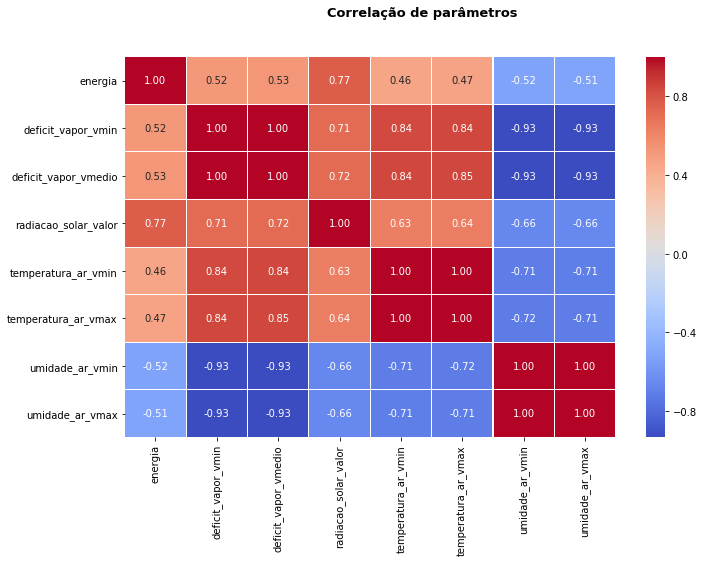

In [68]:
showHeatMap(dfParameters)

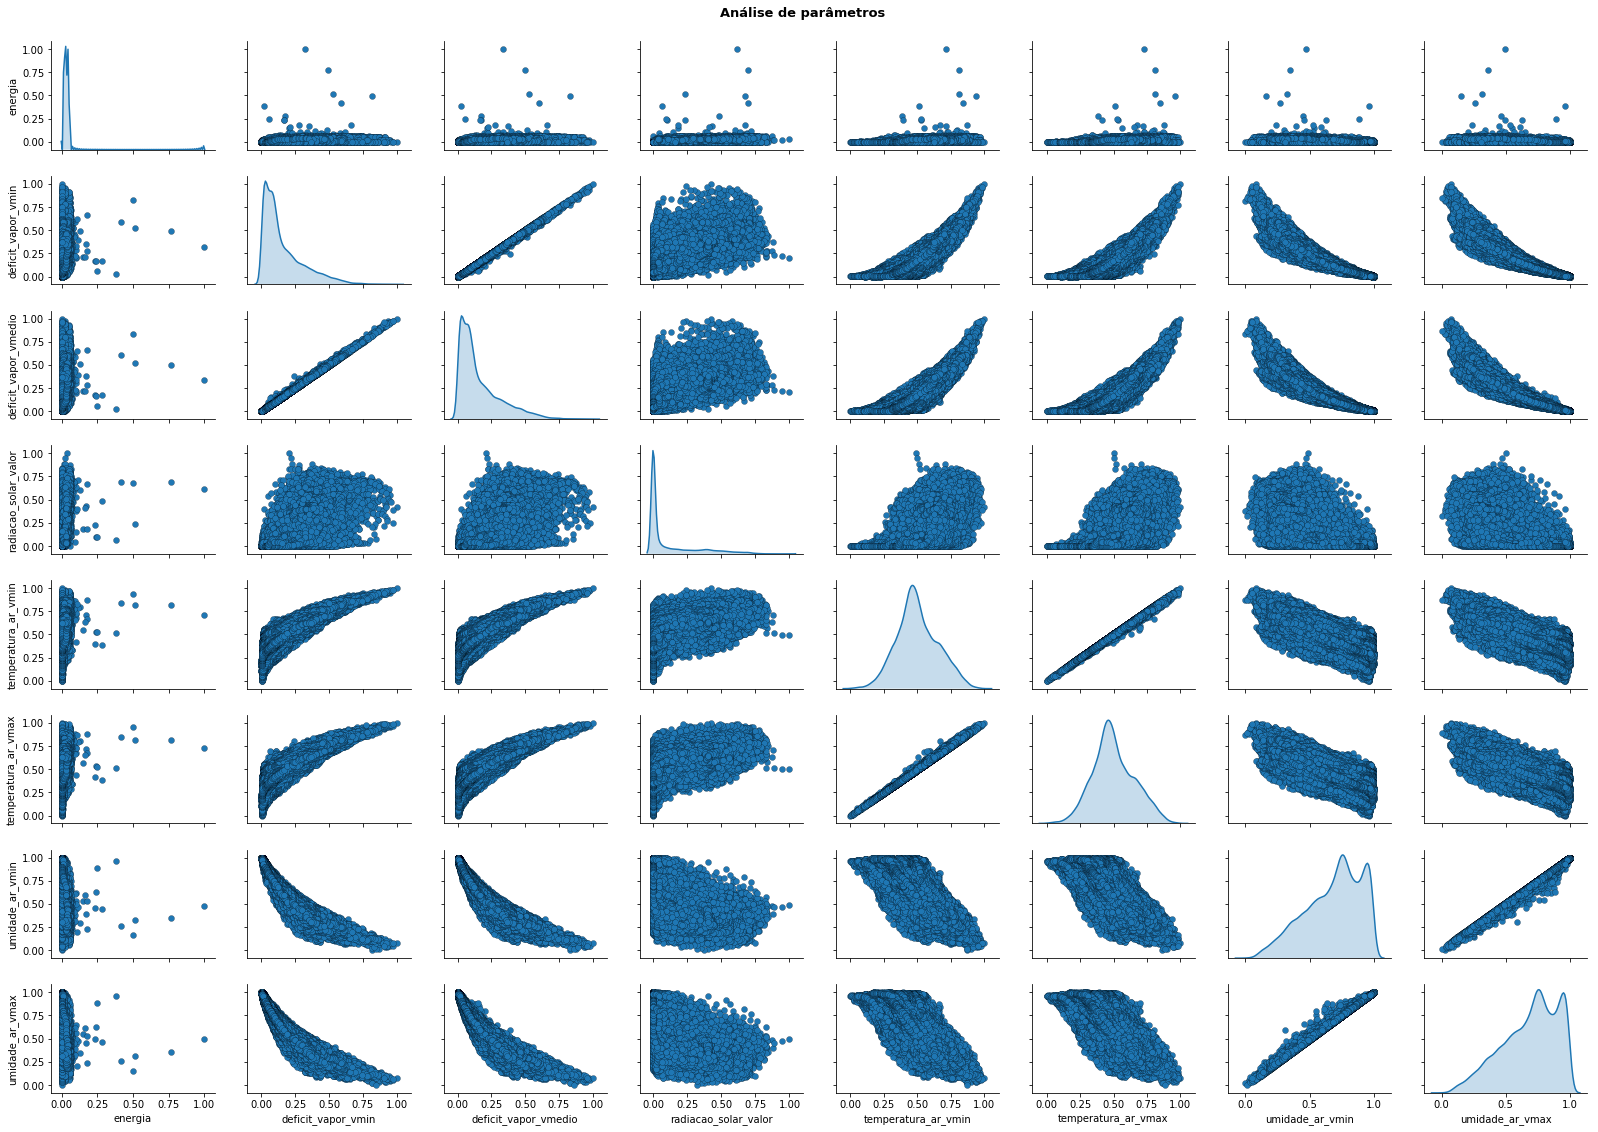

In [69]:
showPairPlot(dfParameters)

In [70]:
#CÉLULA TCC-
X = dfParameters.drop(['energia'],axis=1)
y = dfParameters.energia

In [71]:
#CÉLULA TCC-
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.25, random_state=42)

In [72]:
#CÉLULA TCC-
print(X_train.shape)
print(y_train.shape)

(38185, 7)
(38185,)


In [73]:
#CÉLULA TCC-
print(X_test.shape)
print(y_test.shape)

(12729, 7)
(12729,)


Regressão  Linear

https://towardsdatascience.com/linear-regression-in-python-9a1f5f000606

https://www.dataquest.io/blog/understanding-regression-error-metrics/

https://realpython.com/linear-regression-in-python/

https://www.analyticsvidhya.com/blog/2017/06/a-comprehensive-guide-for-linear-ridge-and-lasso-regression/

https://jovianlin.io/data-visualization-seaborn-part-2/

----------------------------------------------------
----------      REGRESSÃO LINEAR       -------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.000105
RMSE: 0.010270
r²: 63.28 %
MAE: 0.004635
------------------- TESTE ---------------------------
MSE: 0.000155
RMSE: 0.012431
r²: 53.62 %
MAE: 0.004714
----------------------------------------------------


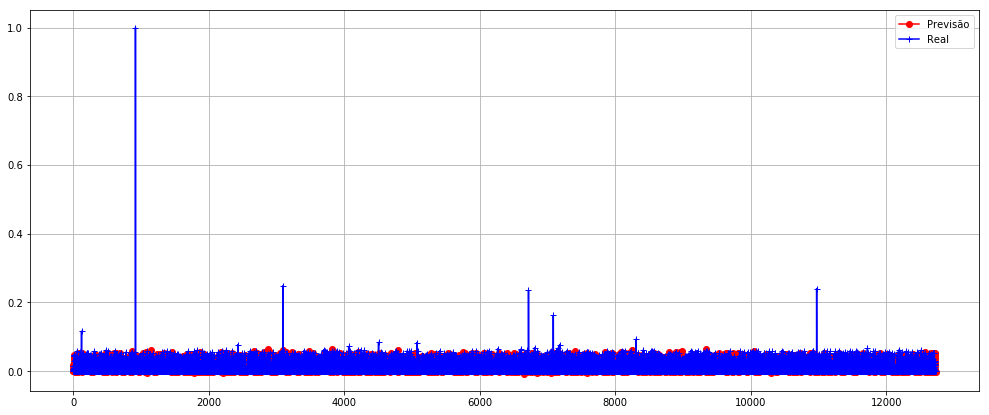

                      0  Coeficiente estimado
0    deficit_vapor_vmin              0.128926
4   temperatura_ar_vmax              0.085449
2  radiacao_solar_valor              0.074519
6       umidade_ar_vmax              0.016611
5       umidade_ar_vmin             -0.036806
3   temperatura_ar_vmin             -0.079852
1  deficit_vapor_vmedio             -0.164742


In [74]:
#CÉLULA TCC-
LinearRegression = linear_model.LinearRegression()

print('----------------------------------------------------')
print('----------      REGRESSÃO LINEAR       -------------')
print('----------------------------------------------------')
modelLinearRegression = showResult(LinearRegression, X_train, y_train, X_test, y_test)
#print(model.intercept_)
coeff = pd.DataFrame(X_train.columns)
coeff['Coeficiente estimado'] = pd.Series(modelLinearRegression.coef_)
coeff.sort_values(by='Coeficiente estimado', inplace=True, ascending=False)
print(coeff)
#print(modelRegLinear.coef_)
#for idx, col_name in enumerate(X_train.columns):
#    print("Ccoeficiente para a coluna '{}': {:.6f}".format(col_name, model.coef_[idx]))


Random Forest Regressor

----------------------------------------------------
------------      RANDOM FOREST     ----------------
----------------------------------------------------
------------------- TREINO -------------------------
MSE: 0.000015
RMSE: 0.003870
r²: 94.79 %
MAE: 0.001439
------------------- TESTE ---------------------------
MSE: 0.000155
RMSE: 0.012470
r²: 53.33 %
MAE: 0.003941
----------------------------------------------------


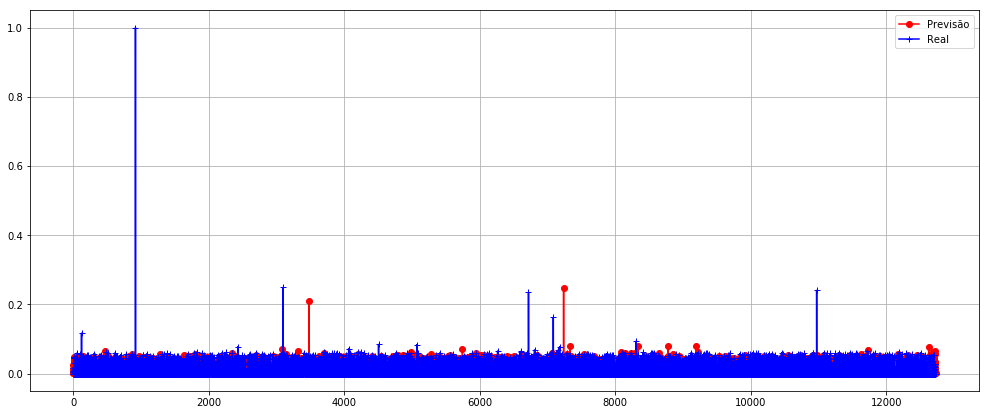

In [75]:
#CÉLULA TCC-
RandomForest = RandomForestRegressor(n_estimators=350, random_state=0)
    
print('----------------------------------------------------')
print('------------      RANDOM FOREST     ----------------')
print('----------------------------------------------------')

modelRandomForest = showResult(RandomForest, X_train, y_train, X_test, y_test)

In [76]:
#MAE é a média da diferença absoluta entre os valores previstos e o valor observado

#O numerador é MSE (média dos quadrados dos residuais) e o denominador é a variância nos valores Y. Quanto mais alto o MSE, menor o R_squared e mais pobre é o modelo.

#Por que você deve escolher R² Ajustado sobre R²?
#Existem alguns problemas com o R² normal que são resolvidos pelo R² Ajustado. Um R² ajustado considerará a melhoria marginal adicionada por um termo adicional em seu modelo. Por isso, aumentará se você adicionar os termos úteis e diminuirá se você adicionar preditores menos úteis. No entanto, o R² aumenta com termos crescentes, mesmo que o modelo não esteja realmente melhorando.

#O R², também chamado de Coeficiente de Determinação, diz o quanto meu modelo está prevendo corretamente.

#RMSE (Root Mean Square Error)(Erro Quadrado Médio da Raiz)
#Representa o desvio padrão da amostra das diferenças entre os valores previstos e os valores observados (chamados resíduos)

In [68]:
#Teste F de Significância global: afirma se ao menos uma variável do meu modelo está relacionada com a variável alvo. Para isso, o valor-p desta estatística precisa ser menor que 0.05

#Teste de Significância individuais ou p-values dos coeficientes: diz o quanto das variáveis preditoras explicam a variável alvo. A métrica padrão é o p-value ser menor que 0.05.

#Coeficiente R²: diz o quanto o meu modelo explica seus resultados. É um valor entre 0 e 1. Quanto mais próximo de 1, melhor.

In [77]:
%matplotlib inline
import matplotlib.pyplot as plt

import numpy as np
import seaborn as sns

def plot_residuals_and_coeff(resid_train, resid_test, coeff):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    axes[0].bar(np.arange(len(resid_train)), resid_train)
    axes[0].set_xlabel("núm. amostras")
    axes[0].set_ylabel("resíduo")
    axes[0].set_title("treino")
    axes[1].bar(np.arange(len(resid_test)), resid_test)
    axes[1].set_xlabel("núm. amostras")
    axes[1].set_ylabel("resíduo")
    axes[1].set_title("teste")
    axes[2].bar(np.arange(len(coeff)), coeff)
    axes[2].set_xlabel("núm. coeficientes")
    axes[2].set_ylabel("coeficiente")
    fig.tight_layout()
    return fig, axes

residuo_treino = y_train - modelRegLinear.predict(X_train)
residuo_teste  = y_test - modelRegLinear.predict(X_test)

fig, ax = plot_residuals_and_coeff(residuo_treino, residuo_teste, modelRegLinear.coef_)

NameError: name 'modelRegLinear' is not defined

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import LinearRegression
from pandas import Series, DataFrame

lasso = Lasso()
lasso.fit(X_train,y_train)
train_score=lasso.score(X_train,y_train)
test_score=lasso.score(X_test,y_test)
coeff_used = np.sum(lasso.coef_!=0)

print("training score:" , train_score)
print("test score: " , test_score)
print("number of features used: ", coeff_used)

lasso001 = Lasso(alpha=0.01, max_iter=10e5)
lasso001.fit(X_train,y_train)

train_score001=lasso001.score(X_train,y_train)
test_score001=lasso001.score(X_test,y_test)
coeff_used001 = np.sum(lasso001.coef_!=0)

print("training score for alpha=0.01:", train_score001)
print("test score for alpha =0.01: ", test_score001)
print("number of features used: for alpha =0.01:", coeff_used001)

lasso00001 = Lasso(alpha=0.0001, max_iter=10e5)
lasso00001.fit(X_train,y_train)

train_score00001=lasso00001.score(X_train,y_train)
test_score00001=lasso00001.score(X_test,y_test)
coeff_used00001 = np.sum(lasso00001.coef_!=0)

print("training score for alpha=0.0001:", train_score00001)
print("test score for alpha =0.0001: ", test_score00001)
print("number of features used: for alpha =0.0001:", coeff_used00001)

lr = LinearRegression()
lr.fit(X_train,y_train)
lr_train_score=lr.score(X_train,y_train)
lr_test_score=lr.score(X_test,y_test)

print("LR training score:", lr_train_score)
print("LR test score: ", lr_test_score)

plt.subplot(1,2,1)
plt.plot(lasso.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Lasso; $\alpha = 1$',zorder=7) # alpha here is for transparency
plt.plot(lasso001.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Lasso; $\alpha = 0.01$') # alpha here is for transparency

plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=4)

plt.subplot(1,2,2)

plt.plot(lasso.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Lasso; $\alpha = 1$',zorder=7) # alpha here is for transparency
plt.plot(lasso001.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Lasso; $\alpha = 0.01$') # alpha here is for transparency
plt.plot(lasso00001.coef_,alpha=0.8,linestyle='none',marker='v',markersize=6,color='black',label=r'Lasso; $\alpha = 0.00001$') # alpha here is for transparency
plt.plot(lr.coef_,alpha=0.7,linestyle='none',marker='o',markersize=5,color='green',label='Linear Regression',zorder=2)

plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=4)
plt.tight_layout()
plt.show()

## 4 - Otimização

## 5 - Resultados

In [ ]:


from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
regressor = RandomForestRegressor(n_estimators = 100)
regressor.fit(X_train, y_train)
feature_importances = regressor.feature_importances_

X_train_opt = X_train.copy()
removed_columns = pd.DataFrame()
models = []
r2s_opt = []

for i in range(0,5):
    least_important = np.argmin(feature_importances)
    removed_columns = removed_columns.append(X_train_opt.pop(X_train_opt.columns[least_important]))
    regressor.fit(X_train_opt, y_train)
    feature_importances = regressor.feature_importances_
    accuracies = cross_val_score(estimator = regressor,
                                 X = X_train_opt,
                                 y = y_train, cv = 5,
                                 scoring = 'r2')
    r2s_opt = np.append(r2s_opt, accuracies.mean())
    models = np.append(models, ", ".join(list(X_train_opt)))
    
feature_selection = pd.DataFrame({'Features':models,'r2 Score':r2s_opt})
feature_selection.head()

